In [ ]:
from flowermd.library import LJChain, RandomWalk, PhantomWalk
import unyt as u
from flowermd.library.forcefields import DPD
import hoomd

npoly = 100 # number of chain
nmono = 100 # number of beads per chain
densities = [0.6, 0.8, 1.0, 1.2, 1.4]
densities_strings = [str(x).replace(".", "_") for x in densities]
runs_per_density = 5

A = 250000
gamma = 1500
kT = 1.0
r_cut = 1.01
bond_k = 250000
bond_r0 = 1.0

log_write_freq = 10
n_steps_dpd = 1000
n_steps_fire = 200

device = hoomd.device.CPU(notice_level=0)

for density in densities:
    for n in range(runs_per_density):
        molecules = LJChain(
            num_mols=npoly,
            lengths=nmono,
            bead_sequence=["_A"],
            bead_mass={"_A": 1.0},
            bond_lengths={"_A-_A": 1.0},
            identify_connections=False,
        )
        
        ref_length = 1.0 * u.Unit("nm")
        ref_mass = 1.0 * u.Unit("g/mol")
        ref_energy = 1.0 * u.Unit("kcal / mol")
        ref_values_dict = {"length": ref_length, "mass": ref_mass, "energy": ref_energy}
        
        system = RandomWalk(
            molecules=molecules,
            density=density * u.Unit("nm**-3"),
            bond_length=1.0,
            base_units=ref_values_dict,
        )
        
        dpd_ff = DPD(
            A=A, gamma=gamma, kT=kT, r_cut=r_cut, bond_k=bond_k, bond_r0=bond_r0
        )
        
        sim = PhantomWalk(
            initial_state=system.hoomd_snapshot,
            forcefield=dpd_ff.hoomd_forces,
            gsd_write_freq=100,
            log_write_freq=log_write_freq,
            n_steps_dpd=n_steps_dpd,
            n_steps_fire=n_steps_fire,
            log_file_name=f"log_density{density}_run{n}.txt",
            gsd_file_name=f"trajectory_density{density}_run{n}.gsd",
            device=device
        )
        
        for writer in sim.operations.writers:
            if isinstance(writer, hoomd.write.GSD):
                writer.flush()

from cmeutils.visualize import FresnelGSD
import PIL

for n, density in enumerate(densities):
    sim_visualizer = FresnelGSD(
        gsd_file=f"trajectory{n}.gsd", frame=-1, view_axis=(1, 1, 1)
    )
    scene = sim_visualizer.view()
    image = PIL.Image.fromarray(scene[:], mode="RGBA")
    image.save(f"densities{n}.png")

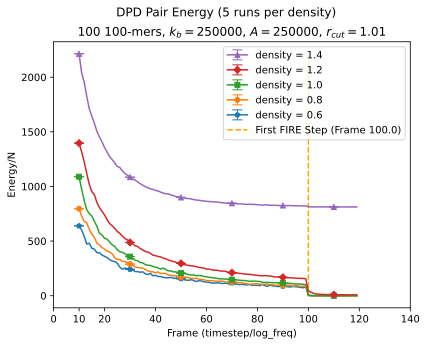

In [12]:
import numpy as np
import matplotlib
import matplotlib_inline
import matplotlib.pyplot as plt
%matplotlib inline
matplotlib.style.use("default")
matplotlib_inline.backend_inline.set_matplotlib_formats("svg")

slice_idx = 10
num_elements = npoly*nmono

fig, ax = plt.subplots()

markers = ["p", "o", "s", "D", "^"]

for i, density in enumerate(densities):
    pairs = []
    for n in range(runs_per_density):
        log = np.genfromtxt(f"log_density{density}_run{n}.txt", names=True)
        pairs.append(log["mdpairDPDenergy"])
    
    pairs_arr = np.array(pairs)
    sliced_pairs = pairs_arr[:, slice_idx:] / num_elements
    
    mean_series = np.mean(sliced_pairs, axis=0)
    x_values = np.arange(slice_idx, pairs_arr.shape[1])
    std_err = np.std(sliced_pairs, axis=0, ddof=1) / np.sqrt(runs_per_density)
    
    ax.errorbar(
            x_values,
            mean_series,
            yerr=std_err,
            label=f"density = {density}",
            marker=markers[i],
            markevery=20,
            errorevery=20,
            markersize=5,
            capsize=5,
            capthick=1,
            elinewidth=1,
        )

first_fire_step = n_steps_dpd/log_write_freq
ax.vlines(x=first_fire_step, ymin=0, ymax=max(pairs[0][slice_idx:])/num_elements, color="orange", linestyle="--", label=f"First FIRE Step (Frame {first_fire_step})")
plt.suptitle(f"DPD Pair Energy ({runs_per_density} runs per density)")
ax.set_title(fr"{npoly} {nmono}-mers, $k_b = {bond_k}$, $A = {A}$, $r_{{cut}} = {r_cut}$")
plt.xlabel("Frame (timestep/log_freq)")
plt.ylabel("Energy/N")
ax.legend(reverse = True)

# Force an x-tick at slice_idx so it's clearer that we're slicing our data to start at slice_idx
x_ticks = list(ax.get_xticks())
x_ticks.append(slice_idx)
ax.set_xticks(x_ticks)

plt.savefig("densities.svg")